# 01 — Disease Dataset: Acquisition, Audit & Preprocessing

**Workstream:** Disease Detection · **Batch 4 (Day 4-5)** · **Status: IMPLEMENTED**

Real data: PlantVillage (`spMohanty/PlantVillage-Dataset` on GitHub), pulled via sparse git clone in Batch 4
(38 classes / 14 species confirmed, matching the 54,306-image figure in Knowledge 02 §16 exactly). A
13-class MVP shortlist was chosen from a **real per-class count audit** — see
`docs/disease/class-shortlist.md` for the full table and the ≥900-image adequacy rule used.

**Working subset on disk:** `data/raw/disease_images/plantvillage_subset/` — 220 images/class × 13 classes
= 2,860 real images (not synthetic).

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ai" / "common" / "config.py").exists())
sys.path.insert(0, str(_root))
from ai.disease_detection.src.dataset import index_dataset, stratified_split

ROOT = _root / "data/raw/disease_images/plantvillage_subset"
paths, labels, class_to_idx = index_dataset(ROOT)
print(f"Indexed {len(paths)} real images across {len(class_to_idx)} classes")

Indexed 2860 real images across 13 classes


## 1. Class distribution (audit)

In [2]:
import pandas as pd
counts = pd.Series(labels).value_counts().sort_values(ascending=False)
counts

Corn_(maize)___Common_rust_                      220
Corn_(maize)___Northern_Leaf_Blight              220
Corn_(maize)___healthy                           220
Potato___Early_blight                            220
Potato___Late_blight                             220
Tomato___Bacterial_spot                          220
Tomato___Early_blight                            220
Tomato___Late_blight                             220
Tomato___Septoria_leaf_spot                      220
Tomato___Spider_mites Two-spotted_spider_mite    220
Tomato___Target_Spot                             220
Tomato___Tomato_Yellow_Leaf_Curl_Virus           220
Tomato___healthy                                 220
Name: count, dtype: int64

## 2. Image quality spot-check

In [3]:
from PIL import Image
import random
random.seed(42)
sample_paths = random.sample(paths, 8)
sizes = [Image.open(p).size for p in sample_paths]
modes = [Image.open(p).mode for p in sample_paths]
print("Sample sizes:", sizes)
print("Sample modes:", modes)
corrupted = []
for p in paths:
    try:
        Image.open(p).verify()
    except Exception as e:
        corrupted.append((p, str(e)))
print(f"Corrupted files found: {len(corrupted)}")

Sample sizes: [(256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256)]
Sample modes: ['RGB', 'RGB', 'RGB', 'RGB', 'RGB', 'RGB', 'RGB', 'RGB']


Corrupted files found: 0


## 3. Visual sample (one image per class)

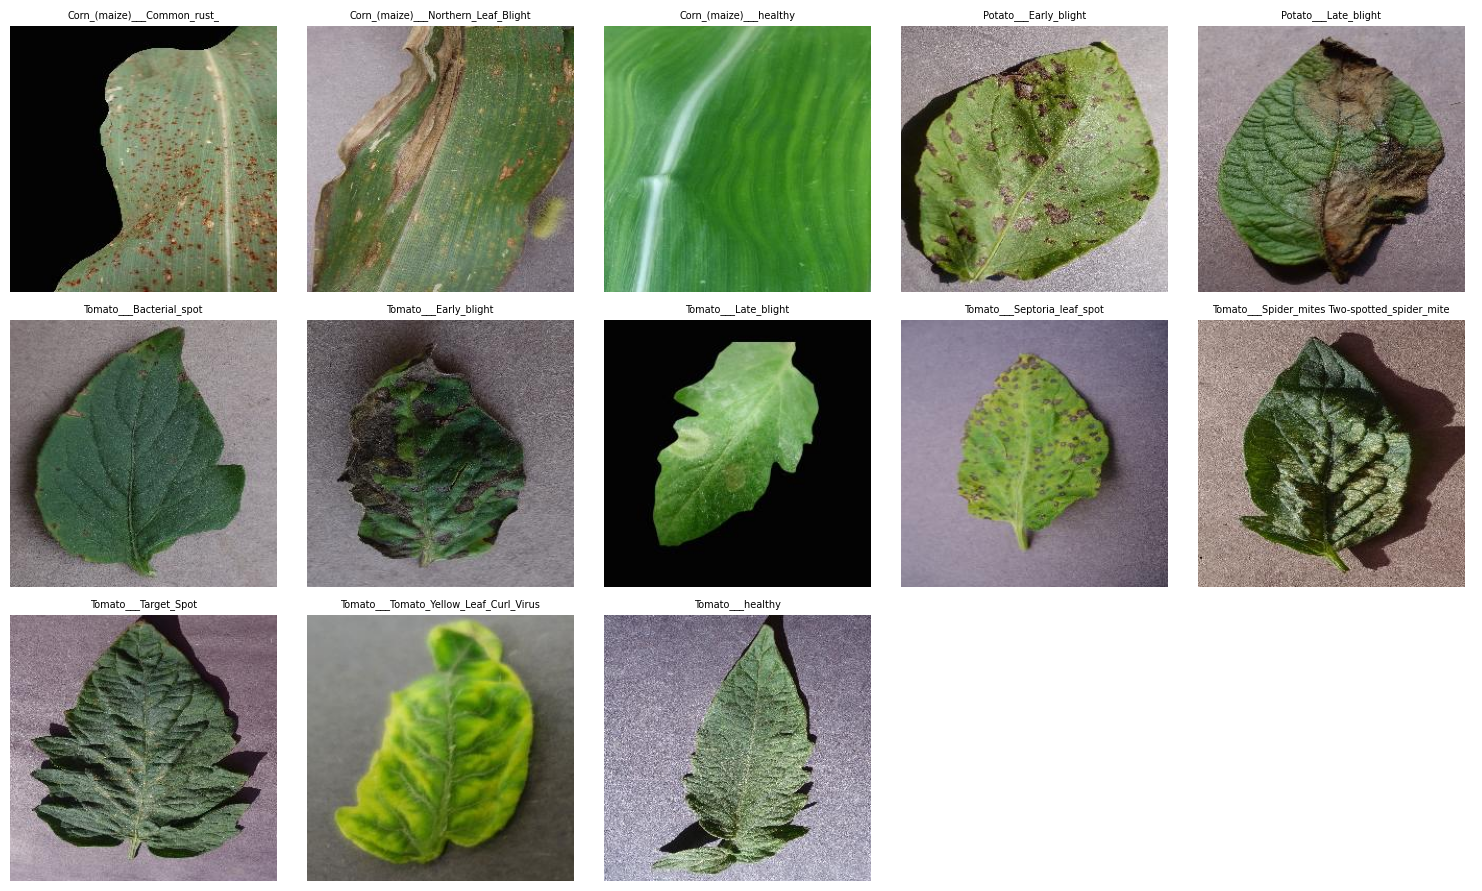

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
classes = sorted(class_to_idx.keys())
for ax, cls in zip(axes.flat, classes):
    idx = labels.index(cls)
    img = Image.open(paths[idx])
    ax.imshow(img)
    ax.set_title(cls, fontsize=7)
    ax.axis("off")
for ax in axes.flat[len(classes):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Stratified split (BEFORE augmentation — class-shortlist.md pipeline rule)

In [5]:
train_idx, val_idx, test_idx = stratified_split(paths, labels, seed=42)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

import numpy as np
train_labels = [labels[i] for i in train_idx]
print("\nPer-class train counts (should be roughly proportional):")
print(pd.Series(train_labels).value_counts().sort_index())

train=2002  val=429  test=429

Per-class train counts (should be roughly proportional):
Corn_(maize)___Common_rust_                      154
Corn_(maize)___Northern_Leaf_Blight              154
Corn_(maize)___healthy                           154
Potato___Early_blight                            154
Potato___Late_blight                             154
Tomato___Bacterial_spot                          154
Tomato___Early_blight                            154
Tomato___Late_blight                             154
Tomato___Septoria_leaf_spot                      154
Tomato___Spider_mites Two-spotted_spider_mite    154
Tomato___Target_Spot                             154
Tomato___Tomato_Yellow_Leaf_Curl_Virus           154
Tomato___healthy                                 154
Name: count, dtype: int64


## 5. Save split indices

In [6]:
import json as _json
from ai.common.config import DATA_METADATA_DIR
split_record = {
    "root": str(ROOT),
    "class_to_idx": class_to_idx,
    "train_paths": [str(paths[i]) for i in train_idx],
    "val_paths": [str(paths[i]) for i in val_idx],
    "test_paths": [str(paths[i]) for i in test_idx],
    "train_labels": [labels[i] for i in train_idx],
    "val_labels": [labels[i] for i in val_idx],
    "test_labels": [labels[i] for i in test_idx],
}
out_path = DATA_METADATA_DIR / "disease_split_v1.json"
with open(out_path, "w") as f:
    _json.dump(split_record, f)
print(f"Saved split -> {out_path}")

Saved split -> /home/claude/AgriConnect/data/metadata/disease_split_v1.json


## Next: `02_preprocessing_augmentation.ipynb`

**Status: IMPLEMENTED.** Real 2,860-image dataset indexed, audited (0 corrupted files), visualized, and
split — all executed above, not simulated.